# From spectral methods to Fourier neural operators

[![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?style=flat-square&logo=googlecolab)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/05-fno/fno-spectral-methods.ipynb)

The best way to understand a **Fourier Neural Operator (FNO)** is to connect three ideas:

1. **Fourier analysis:** Any complicated spatial pattern can be represented as a combination of simple waves.
2. **Physics:** Many physical processes act on these waves in predictable ways.
3. **Machine learning:** Instead of deriving how physics transforms each wave, we can learn that transformation from data.

The surprising thing is that **FNO is closely related to classical Fourier spectral methods for solving PDEs.** The main difference is that FNO learns the transformation rather than deriving it from the governing equations.

This page writes out that connection as one derivation. In the [heat flow lab](https://kks32-courses.github.io/sciml/05-fno/fno-intuition.html) you can watch the same steps on a ring and fit the multipliers yourself.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

N = 128
x = np.linspace(0, 2*np.pi, N, endpoint=False)


def ddx(u):
    # Differentiate a periodic field: multiply its Fourier coefficients by ik.
    wavenumber = np.fft.rfftfreq(u.size, d=1/u.size)
    return np.fft.irfft(1j*wavenumber*np.fft.rfft(u), n=u.size)


def amplitudes(u, kmax):
    # Amplitude of each real wave in u for the wavenumbers 0..kmax.
    c = np.abs(np.fft.rfft(u, norm='forward'))
    c[1:] *= 2
    return c[:kmax + 1]

In [2]:
# Plotting helpers. The course site hides this cell.
BLUE, GREEN, ORANGE, PURPLE = '#4d85ca', '#399e89', '#db6a20', '#7251a1'
INK, RULE = '#253349', '#b5bdc5'


def show_waves(rows):
    # Draw each (label, field, color) on its own axis over one period.
    fig, axes = plt.subplots(len(rows), 1, figsize=(7.5, 1.55*len(rows) + 0.35),
                             sharex=True, sharey=True, squeeze=False)
    for ax, (label, field, color) in zip(axes[:, 0], rows):
        ax.axhline(0, color=RULE, lw=1)
        ax.plot(np.append(x, 2*np.pi), np.append(field, field[0]), color=color, lw=2)
        ax.set_title(label, loc='left', fontsize=11, color=INK)
        ax.set(xlim=(0, 2*np.pi), xticks=[0, np.pi, 2*np.pi], yticks=[-1, 0, 1])
        ax.set_xticklabels(['0', 'π', '2π'])
        ax.tick_params(colors=INK, labelsize=9, length=0)
        for side in ('top', 'right', 'left', 'bottom'):
            ax.spines[side].set_visible(False)
    axes[-1, 0].set_xlabel('Position x', color=INK)
    fig.tight_layout()
    plt.show()


def bar_label(v):
    if v < 5e-4:
        return '0'
    return f'{v:.2g}' if v < 0.1 else f'{v:.3g}'


def show_modes(panels, modes, sharey=False, title=None):
    # Draw each (label, values, color) as bars over the wavenumbers in modes.
    fig, axes = plt.subplots(1, len(panels), figsize=(3.4*len(panels), 2.9),
                             sharey=sharey, squeeze=False)
    tallest = max(np.max(values) for _, values, _ in panels)
    for ax, (label, values, color) in zip(axes[0], panels):
        bars = ax.bar(modes, values, width=0.62, color=color)
        ax.bar_label(bars, labels=[bar_label(v) for v in values], padding=2, fontsize=8, color=INK)
        ax.set_title(label, fontsize=10.5, color=INK)
        ax.set(xticks=modes, yticks=[], ylim=(0, 1.18*(tallest if sharey else np.max(values))))
        ax.set_xlabel('Frequency k', color=INK)
        ax.tick_params(colors=INK, labelsize=9, length=0)
        for side in ('top', 'right', 'left'):
            ax.spines[side].set_visible(False)
        ax.spines['bottom'].set_color(RULE)
    if title:
        fig.suptitle(title, fontsize=11.5, color=INK)
    fig.tight_layout()
    plt.show()

## 1. Heat on a rod as a sum of waves

### Imagine heat spreading along a metal rod

Suppose the temperature initially looks like this:

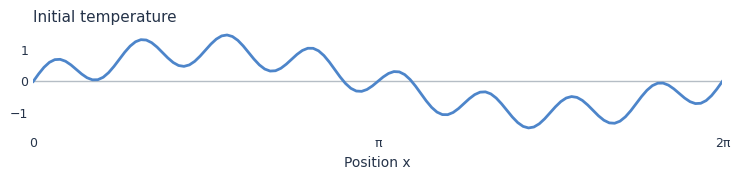

In [3]:
u0 = np.sin(x) + 0.5*np.sin(8*x)
show_waves([('Initial temperature', u0, BLUE)])

There are broad hot and cold regions, but also small, rapid temperature fluctuations.

Fourier tells us this complicated temperature curve can be built by adding simpler waves:

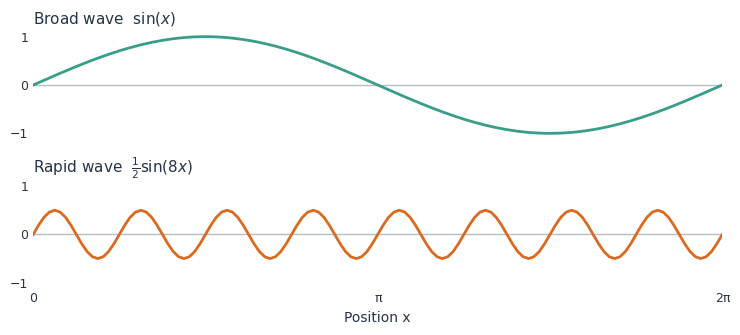

In [4]:
show_waves([(r'Broad wave  $\sin(x)$', np.sin(x), GREEN),
            (r'Rapid wave  $\frac{1}{2}\sin(8x)$', 0.5*np.sin(8*x), ORANGE)])

You can think of the temperature field as a musical chord. A chord is composed of different notes; a temperature field is composed of different spatial frequencies.

**The Fourier transform (FFT) tells us how much of each wave is present.**

It does not learn anything. It is simply a mathematical change of representation.

### The beautiful part: Physics acts differently on each wave

Consider the heat equation:

$$\frac{\partial u}{\partial t}=\nu\frac{\partial^2u}{\partial x^2}$$

Suppose our temperature is just one wave:

$$u(x,0)=\sin(kx)$$

The second derivative gives:

$$\frac{\partial^2}{\partial x^2}\sin(kx)=-k^2\sin(kx)$$

Notice something remarkable: **the spatial shape doesn't change!**

Only its amplitude changes.

In fact, the exact solution is

$$u(x,t)=\underbrace{e^{-\nu k^2t}}_{\text{amplitude reduction}}\sin(kx)$$

This is the key idea.

- Low frequencies (small $k$) decay slowly.
- High frequencies (large $k$) decay rapidly.

Heat diffusion smooths out small fluctuations much faster than large-scale variations.

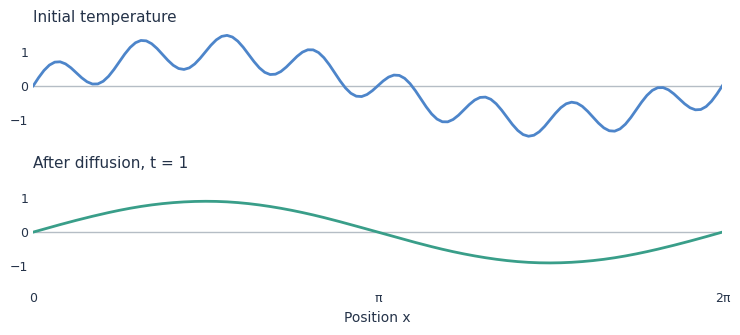

In [5]:
nu, t = 0.1, 1.0
u_t = np.exp(-nu*t)*np.sin(x) + 0.5*np.exp(-64*nu*t)*np.sin(8*x)
show_waves([('Initial temperature', u0, BLUE), (f'After diffusion, t = {t:g}', u_t, GREEN)])

The rapid oscillations nearly disappear, but the broad wave remains.

Why does the decay rate grow like $k^2$? Look at the wave $\sin(kx)$. Its hot spots and cold spots sit a distance $\pi/k$ apart, and heat has to cross that distance to even them out. Diffusion crosses a distance $d$ in a time of about $d^2/\nu$, so the wave lives for a time proportional to $1/(\nu k^2)$. Halve the wavelength and the wave dies four times sooner. In the figure, $\nu=0.1$ and $t=1$. The broad wave $\sin(x)$ keeps $e^{-0.1}=0.905$ of its amplitude, and the rapid wave $\sin(8x)$ keeps $e^{-6.4}=0.0017$.

This means we can solve the heat equation without directly computing spatial derivatives at every grid point.

We Fourier-transform the initial temperature, multiply each frequency by its known decay factor, and transform back:

$$\boxed{\widehat u(k,t)=e^{-\nu k^2t}\,\widehat u(k,0)}$$

That's the foundation of Fourier spectral methods.

## 2. The multiplier from the heat equation

This is the crucial connection between **classical spectral methods and Fourier Neural Operators**.

In the heat equation example, we wrote

$$\widehat u(k,t)=\underbrace{e^{-\nu k^2t}}_{R(k,t)}\widehat u(k,0)$$

But where did $R(k,t)$ come from?

**We didn't learn $R$. We derived it directly from the PDE.**

Let's derive it intuitively, following the logic of Fourier spectral methods.

### Start with the heat equation

Consider a metal rod with a temperature distribution $u(x,t)$:

$$\frac{\partial u}{\partial t}=\nu\frac{\partial^2u}{\partial x^2}$$

The equation says that temperature changes according to the spatial curvature of the temperature field.

Imagine a temperature field composed of several waves:

$$u(x,t)=q_1(t)\sin(x)+q_2(t)\sin(2x)+q_3(t)\sin(3x)$$

The important idea is that the spatial waves are fixed, but their amplitudes $q_1,q_2,q_3$ can change with time.

We want to find how those amplitudes evolve.

### First, study just one wave

Suppose the initial temperature is

$$u(x,0)=\sin(2x)$$

We guess that the wave keeps its shape as it diffuses, while its amplitude changes:

$$u(x,t)=q(t)\sin(2x)$$

Substitute this into the heat equation.

On the left:

$$\frac{\partial u}{\partial t}=q'(t)\sin(2x)$$

On the right, differentiate twice with respect to $x$:

$$\frac{\partial^2u}{\partial x^2}=-4q(t)\sin(2x)$$

So the PDE becomes

$$q'(t)\sin(2x)=-4\nu q(t)\sin(2x)$$

The $\sin(2x)$ factor is common to both sides. We can equate the amplitudes:

$$\boxed{q'(t)=-4\nu q(t)}$$

This is the key simplification.

**We turned a PDE involving space and time into an ODE involving only time.**

And the ODE is easy to solve:

$$q(t)=q(0)e^{-4\nu t}$$

Therefore,

$$u(x,t)=e^{-4\nu t}\sin(2x)$$

The amplitude decays exponentially, but the spatial wave remains the same.

### Generalize to every frequency

For an arbitrary wave $\sin(kx)$, we know:

$$\frac{d^2}{dx^2}\sin(kx)=-k^2\sin(kx)$$

The resulting amplitude equation is

$$\frac{dq_k}{dt}=-\nu k^2q_k$$

which gives

$$\boxed{q_k(t)=e^{-\nu k^2t}q_k(0)}$$

And there is our $R$:

$$\boxed{R(k,t)=e^{-\nu k^2t}}$$

Notice that $R$ is not an arbitrary choice. It follows from two properties:

1. Sine waves are eigenfunctions of the second-derivative operator (for suitable boundary conditions).
2. The heat equation makes each wave's amplitude obey an exponential-decay ODE.

### The spectral-method viewpoint

The mathematics becomes particularly elegant with Fourier transforms.

Write the temperature as a sum of complex exponential waves:

$$u(x,t)=\sum_k\widehat u(k,t)e^{ikx}$$

Here, $e^{ikx}$ represents a wave and $\widehat u(k,t)$ tells us how much of that wave is present.

Differentiating twice:

$$\frac{\partial^2u}{\partial x^2}=\sum_k(-k^2)\widehat u(k,t)e^{ikx}$$

Substitute into the heat equation:

$$\sum_k\frac{d\widehat u(k,t)}{dt}e^{ikx}=-\nu\sum_k k^2\widehat u(k,t)e^{ikx}$$

Because the Fourier waves are linearly independent, their coefficients must agree:

$$\boxed{\frac{d\widehat u(k,t)}{dt}=-\nu k^2\widehat u(k,t)}$$

Now we have one independent ODE for each frequency.

Solving them gives

$$\widehat u(k,t)=e^{-\nu k^2t}\widehat u(k,0)$$

In Fourier space, the entire PDE has become **multiplication by $R(k,t)$**.

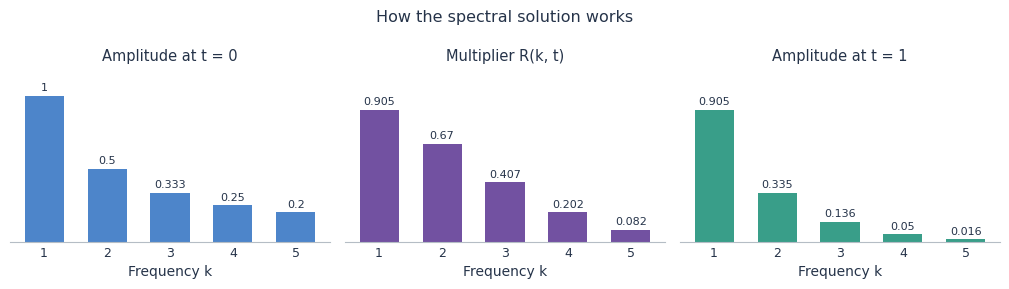

In [6]:
modes = np.arange(1, 6)
initial = 1/modes
R = np.exp(-nu*modes**2*t)
show_modes([('Amplitude at t = 0', initial, BLUE),
            ('Multiplier R(k, t)', R, PURPLE),
            (f'Amplitude at t = {t:g}', R*initial, GREEN)],
           modes, sharey=True, title='How the spectral solution works')

Each Fourier coefficient is multiplied by its own decay factor. The higher frequencies shrink more rapidly.

### How do we implement this numerically?

For a periodic rod, suppose we know the temperature at $N$ equally spaced locations:

$$u_j=u(x_j,0)$$

The Fourier spectral solution is just three operations:

1. **FFT.** Convert the sampled temperature into Fourier coefficients $\widehat u_k(0)$.
2. **Multiply by the exact physics.** $\widehat u_k(t)=R(k,t)\widehat u_k(0)$
3. **Inverse FFT.** Transform those coefficients back into a temperature distribution $u(x,t)$.

In Python, the full spectral solution is remarkably short:

In [7]:
import numpy as np

N = 128
L = 2 * np.pi
x = np.linspace(0, L, N, endpoint=False)

nu = 0.1
t = 1.0

u0 = np.sin(x) + 0.5 * np.sin(8*x)

# Step 1: Fourier transform
u_hat = np.fft.fft(u0)

# Physical angular wavenumbers
k = 2*np.pi*np.fft.fftfreq(N, d=L/N)

# Step 2: Physics-derived multiplier
R = np.exp(-nu * k**2 * t)
u_hat_new = R * u_hat

# Step 3: Reconstruct temperature
u_new = np.fft.ifft(u_hat_new).real

exact = np.exp(-nu*t)*np.sin(x) + 0.5*np.exp(-64*nu*t)*np.sin(8*x)
print(f"max error: {np.abs(u_new - exact).max():.1e}")

max error: 5.6e-16


No neural network. No training. We derive the evolution mathematically.

For this periodic constant-coefficient heat equation, it is the exact evolution of the retained Fourier modes, up to numerical roundoff. The last line of the cell compares the result with the exact solution $e^{-\nu t}\sin(x)+\tfrac12e^{-64\nu t}\sin(8x)$.

### An even more general mathematical connection

A PDE can be written abstractly as

$$\frac{du}{dt}=\mathcal Lu$$

where $\mathcal L$ is a linear differential operator.

Its solution is formally

$$\boxed{u(t)=e^{t\mathcal L}u(0)}$$

If the Fourier basis diagonalizes $\mathcal L$, then for every wave,

$$\mathcal L e^{ikx}=\lambda_k e^{ikx}$$

and the corresponding exact multiplier is

$$\boxed{R(k,t)=e^{t\lambda_k}}$$

For the heat equation,

$$\lambda_k=-\nu k^2$$

so

$$R(k,t)=e^{-\nu k^2t}$$

This is why exponentials appear naturally in spectral solutions of linear evolution PDEs.

The same formula tells us what other equations do to a wave. Take pure transport, $u_t=-c\,u_x$. Now $\lambda_k=-ick$ is imaginary, so $R(k,t)=e^{-ickt}$ has magnitude one. The wave keeps its height and slides a distance $ct$. The magnitude of $R$ changes the height of a wave, and the phase of $R$ moves it.

| Equation | $\lambda_k$ | $R(k,t)$ | What happens to the wave $e^{ikx}$ |
|---|---|---|---|
| Heat, $u_t=\nu u_{xx}$ | $-\nu k^2$ | $e^{-\nu k^2t}$ | It shrinks and stays in place |
| Transport, $u_t=-c\,u_x$ | $-ick$ | $e^{-ickt}$ | It keeps its height and shifts by $ct$ |
| Both, $u_t=-c\,u_x+\nu u_{xx}$ | $-ick-\nu k^2$ | $e^{-ickt}\,e^{-\nu k^2t}$ | It shrinks and shifts |

**The central insight:** Fourier analysis isn't making an approximation to the physics here. It is revealing a basis in which the differential operator becomes diagonal, so solving the PDE reduces to independently evolving wave amplitudes.

## 3. A multiplier learned from data

### What if we don't know the physical transformation?

This is where FNO enters.

In the heat equation, we derived the factor

$$R(k)=e^{-\nu k^2t}$$

But imagine a more complicated system with unknown or difficult physics.

What if, instead of deriving $R(k)$, we **learned it from examples**?

We show the neural network many pairs of fields:

$$\text{Initial field}\quad\longrightarrow\quad\text{Resulting field}$$

And ask it to learn the relationship.

A Fourier layer performs:

$$\boxed{v_{\mathrm{out}}(x)=\mathcal F^{-1}\left[R_\theta(k)\,\widehat v(k)\right](x)}$$

Here:

- $\widehat v(k)$ is the Fourier transform of the input field.
- $R_\theta(k)$ is a matrix of learned weights for frequency $k$.
- Multiplying them transforms the Fourier coefficients.
- The inverse FFT reconstructs the spatial field.

**The waves themselves are fixed. The learned parameters determine how the waves are transformed.**

Importantly, FNO usually has multiple feature channels, so $R_\theta(k)$ is a matrix rather than a single scalar. The learned weights are complex numbers, so each one can change the height of a wave and shift it, as in the table above.

Section 5 of the [heat flow lab](https://kks32-courses.github.io/sciml/05-fno/fno-intuition.html) does this fit for three waves. It recovers $R(1)$, $R(3)$, and $R(7)$ from 64 pairs of fields, and they match the decay factors of the heat equation.

### What does an actual FNO layer do?

A typical FNO layer is:

$$v_{\ell+1}(x)=\sigma\left(W_\ell v_\ell(x)+\mathcal F^{-1}\left[R_\ell(k)\,\widehat v_\ell(k)\right](x)\right)$$

The $W_\ell v_\ell(x)$ term is a learned pointwise transformation, and $\sigma$ is a nonlinear activation.

Why do we need the nonlinearity? Because the physics of nonlinear systems does more than amplify individual waves. **Different waves interact and create new frequencies.** A simple per-frequency multiplier cannot capture that by itself.

The [FNO block page](https://kks32-courses.github.io/sciml/05-fno/fno-block.html) steps through this layer one operation at a time.

### How is this different from a CNN?

Imagine predicting heat flow using two networks.

A CNN looks at nearby temperatures and learns how neighboring points influence one another. To communicate information across a large distance, it generally needs multiple layers or larger receptive fields.

An FNO transforms the entire field into spatial frequencies. Each Fourier coefficient captures information across the whole domain. Changing that coefficient can therefore affect the reconstruction everywhere.

| CNN | FNO |
|---|---|
| Learns local spatial filters | Learns transformations of global Fourier modes |
| Works primarily with neighboring pixels | Works with spatial frequency coefficients |
| Expands its receptive field through layers | Each Fourier layer has global spatial reach |
| Naturally grid-based | Can often transfer across grid resolutions |

However, FNO's resolution transfer is not the same as guaranteeing accuracy at arbitrary resolutions. It depends on the learned spectral content and on whether the relevant physical scales are resolved.

The [CNN and discretization notebook](https://kks32-courses.github.io/sciml/05-fno/fno-cnn-comparisons.html) runs this comparison for heat flow on grids of 128, 256, and 512 points.

### Why this is important for understanding FNO

Compare the two approaches:

| Classical spectral method | Fourier Neural Operator |
|---|---|
| Fourier basis is fixed | Fourier basis is fixed |
| $R(k)$ comes from the PDE | $R_\theta(k)$ is learned from data |
| Exact exponential for this heat equation | Learned matrices acting on feature channels |
| Direct solution for linear heat diffusion | Multiple nonlinear layers for more complex operators |

But here's an important subtlety.

In classical spectral methods, $R(k)$ emerges so simply because Fourier waves are eigenfunctions of the differential operator:

$$\frac{d^2}{dx^2}e^{ikx}=-k^2e^{ikx}$$

A heterogeneous diffusion equation,

$$\frac{\partial u}{\partial t}=\frac{\partial}{\partial x}\left(\nu(x)\frac{\partial u}{\partial x}\right),$$

doesn't generally produce one independent multiplier for each wave. Different Fourier modes become coupled.

We can see the coupling by hand. Let the diffusivity vary along the rod as $\nu(x)=1+\tfrac12\cos x$, and feed in the single wave $u=\sin(2x)$. The flux is a product of two functions of $x$,

$$\nu(x)\frac{\partial u}{\partial x}=\left(1+\tfrac12\cos x\right)2\cos(2x)=2\cos(2x)+\tfrac12\cos(x)+\tfrac12\cos(3x),$$

and one more derivative gives

$$\frac{\partial}{\partial x}\left(\nu(x)\frac{\partial u}{\partial x}\right)=-4\sin(2x)-\tfrac12\sin(x)-\tfrac32\sin(3x).$$

One wave went in and three came out. The product with $\cos x$ moved part of mode 2 into its neighbors, modes 1 and 3. No single number $R(2)$ can describe that. In the Fourier basis this operator is a full matrix, where the heat equation with constant $\nu$ gave a diagonal one. The next cell checks the three amplitudes.

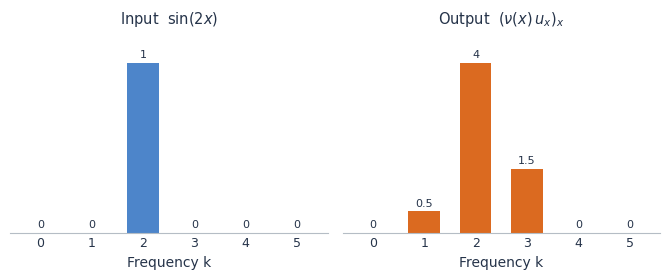

In [8]:
u = np.sin(2*x)
out = ddx((1 + 0.5*np.cos(x))*ddx(u))
show_modes([(r'Input  $\sin(2x)$', amplitudes(u, 5), BLUE),
            (r'Output  $(\nu(x)\,u_x)_x$', amplitudes(out, 5), ORANGE)],
           np.arange(6))

Similarly, nonlinear PDEs can transfer energy between modes.

So the deeper distinction is not merely that FNO learns a different $R(k)$. **Classical spectral methods solve equations in a Fourier basis, while FNO learns a nonlinear composition of Fourier-domain and pointwise transformations to approximate a solution operator.**

The next interesting question is: **If the Fourier basis is fixed and FNO learns only the transformations, how can it represent nonlinear PDEs where waves interact?** That question gets to the heart of what makes FNO work, and where its limitations come from.

## 4. What makes FNO work?

This is the most interesting part of FNO, because it connects directly to **pseudo-spectral methods for nonlinear PDEs**.

The central insight is:

**A Fourier multiplier alone cannot capture nonlinear interactions between waves. But applying a nonlinear function in physical space mixes Fourier frequencies. FNO alternates between these two operations.**

Let's derive why that works.

### Why a Fourier multiplier is insufficient

Consider the linear heat equation. We derived:

$$\widehat u(k,t)=R(k,t)\,\widehat u(k,0)$$

where

$$R(k,t)=e^{-\nu k^2t}$$

Each Fourier mode evolves independently.

Suppose the initial field is

$$u(x,0)=\sin(x)$$

The heat equation can reduce the amplitude of $\sin(x)$, but it cannot generate a $\sin(2x)$ wave.

The first frequency stays the first frequency.

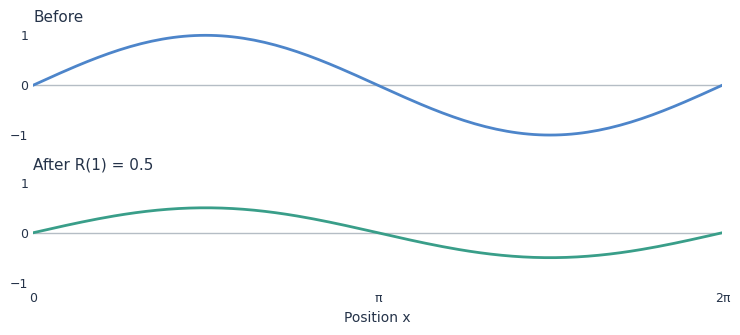

In [9]:
show_waves([('Before', np.sin(x), BLUE), ('After R(1) = 0.5', 0.5*np.sin(x), GREEN)])

A linear Fourier multiplier changes the amplitude, not the spatial frequency.

If we stack ten purely linear Fourier multiplier layers, the result is still a linear transformation. Two such layers give $R_2(k)R_1(k)\,\widehat u(k)$, which is again one multiplier. No new frequency interactions arise.

That is a problem for nonlinear PDEs.

### Nonlinear physics creates new frequencies

Take the viscous Burgers equation:

$$\frac{\partial u}{\partial t}+u\frac{\partial u}{\partial x}=\nu\frac{\partial^2u}{\partial x^2}$$

Focus on the nonlinear term:

$$u\frac{\partial u}{\partial x}$$

Suppose the initial field is

$$u(x,0)=\sin(x)$$

Then

$$\frac{\partial u}{\partial x}=\cos(x)$$

and therefore

$$u\frac{\partial u}{\partial x}=\sin(x)\cos(x)$$

Using a trigonometric identity,

$$\boxed{\sin(x)\cos(x)=\frac12\sin(2x)}$$

Look at what happened!

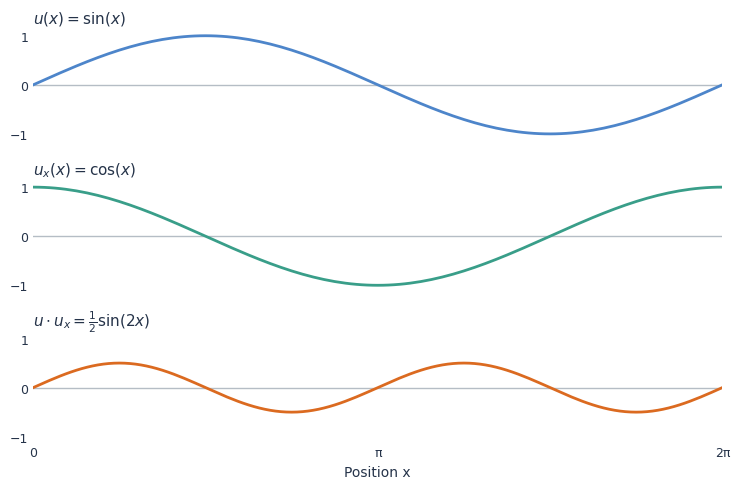

In [10]:
u = np.sin(x)
show_waves([(r'$u(x)=\sin(x)$', u, BLUE),
            (r'$u_x(x)=\cos(x)$', np.cos(x), GREEN),
            (r'$u\cdot u_x=\frac{1}{2}\sin(2x)$', u*np.cos(x), ORANGE)])

Multiplication in physical space generates a wave with twice the original frequency.

The nonlinear term generates a second harmonic even though the initial condition contained only the first harmonic.

In fact, the Burgers equation initially gives:

$$\left.\frac{\partial u}{\partial t}\right|_{t=0}=-\frac12\sin(2x)-\nu\sin(x)$$

The $\sin(2x)$ component is created immediately.

**This is wave interaction.** Nonlinearity creates new Fourier frequencies that were not present in the input.

### What does that look like in Fourier space?

Here is the mathematical principle:

**Two very different operations**

**Linear spatial differentiation**

$$\widehat{u_x}(k)=ik\,\widehat u(k)$$

Each Fourier mode is multiplied independently.

**Nonlinear spatial multiplication**

$$\widehat{u^2}(k)=\sum_p\widehat u(p)\,\widehat u(k-p)$$

Different Fourier modes interact to produce new modes.

This second operation is called a **convolution in Fourier space**.

For example, frequencies $k_1$ and $k_2$, when multiplied in physical space, can produce frequencies $k_1+k_2$ and $k_1-k_2$.

This is the key property underlying nonlinear spectral methods.

Try the sum on $u=\sin x$. Its only coefficients are $\widehat u(1)=\tfrac{1}{2i}$ and $\widehat u(-1)=-\tfrac{1}{2i}$. At $k=2$ the only pair is $p=1$ with $k-p=1$, and it gives $\widehat u(1)^2=-\tfrac14$. Mode $-2$ gets the same value. At $k=0$ the two pairs $(1,-1)$ and $(-1,1)$ give $2\,\widehat u(1)\,\widehat u(-1)=\tfrac12$. So

$$u^2=\tfrac12-\tfrac14e^{2ix}-\tfrac14e^{-2ix}=\tfrac12-\tfrac12\cos(2x),$$

and the square of a wave at mode 1 lands on modes $1+1=2$ and $1-1=0$.

### How do classical pseudo-spectral methods handle this?

Instead of computing the expensive convolution explicitly, a pseudo-spectral solver exploits a simple trick:

- Differentiate in Fourier space, where differentiation is multiplication by $ik$.
- Transform back into physical space.
- Multiply the fields pointwise, computing $u(x)u_x(x)$.
- Fourier-transform that product to obtain its frequency components.

| Space | Operation | Result |
|---|---|---|
| Fourier | Differentiate: $ik\,\widehat u(k)$ | Fourier coefficients of $u_x$ |
| Fourier to physical | Inverse FFT | Recover $u(x)$ and $u_x(x)$ |
| Physical | Multiply $u(x)u_x(x)$ | Creates new frequency components |
| Physical to Fourier | FFT | Nonlinear term in Fourier space. Use it to advance the PDE in time |

This is a beautiful numerical idea: use Fourier space for differentiation and physical space for nonlinear multiplication.

The next cell runs these four steps on $u=\sin(x)$ and compares the product with $\tfrac12\sin(2x)$.

max |u u_x - sin(2x)/2|: 7.0e-15


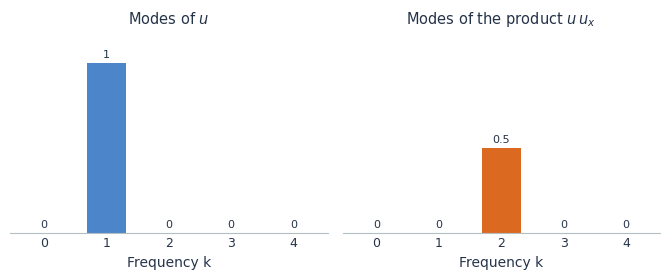

In [11]:
wavenumber = np.fft.rfftfreq(N, d=1/N)
u_hat = np.fft.rfft(np.sin(x))

u_x_hat = 1j*wavenumber*u_hat            # differentiate in Fourier space
u = np.fft.irfft(u_hat, n=N)             # back to physical space
u_x = np.fft.irfft(u_x_hat, n=N)
product = u*u_x                          # multiply at each grid point
product_hat = np.fft.rfft(product)       # nonlinear term in Fourier space

error = np.abs(product - 0.5*np.sin(2*x)).max()
print(f"max |u u_x - sin(2x)/2|: {error:.1e}")
show_modes([(r'Modes of $u$', amplitudes(u, 4), BLUE),
            (r'Modes of the product $u\,u_x$', amplitudes(product, 4), ORANGE)],
           np.arange(5), sharey=True)

Practical pseudo-spectral methods also need dealiasing to prevent unresolved high frequencies from contaminating resolved modes.

### Now look at the FNO architecture

An FNO layer is

$$\boxed{v_{\ell+1}(x)=\sigma\left(W_\ell v_\ell(x)+\mathcal F^{-1}\left[R_\ell(k)\,\widehat v_\ell(k)\right](x)\right)}$$

Notice what happens:

1. **Fourier transform.** Convert the input features into Fourier coefficients.
2. **Learned spectral transformation $R_\ell(k)$.** Transform and mix the feature channels at each retained frequency. This operation by itself is linear.
3. **Inverse FFT and pointwise transformation.** Return to physical space and add $W_\ell v_\ell(x)$.
4. **Nonlinear activation $\sigma$.** This operation creates new frequency interactions.
5. **Repeat.** The next Fourier layer acts on the newly created frequency content.

This is conceptually similar to the alternation used in pseudo-spectral methods.

But the difference is important: a pseudo-spectral method evaluates a known nonlinear PDE term such as $uu_x$. An FNO applies a learned transformation followed by a generic activation such as GELU.

It learns from data which combinations of these operations approximate the desired physical solution operator.

### But can a simple activation really create new waves?

Yes! Let's prove it.

For simplicity, imagine using a square activation,

$$\sigma(z)=z^2$$

This is not the usual FNO activation, but it makes the frequency interaction obvious.

Suppose the Fourier layer produces

$$z(x)=\sin(x)$$

Apply the nonlinear activation:

$$v(x)=\sigma(z(x))=\sin^2(x)$$

Using the identity

$$\boxed{\sin^2(x)=\frac12-\frac12\cos(2x)}$$

We have created two frequency components:

- A constant component, $k=0$.
- A second harmonic, $k=2$.

Neither requires a separately learned Fourier basis.

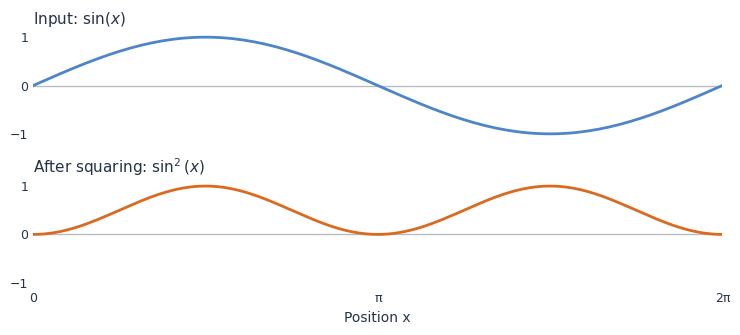

In [12]:
z = np.sin(x)
show_waves([(r'Input: $\sin(x)$', z, BLUE),
            (r'After squaring: $\sin^2(x)$', z**2, ORANGE)])

Squaring a single sine wave produces a constant component and a second harmonic. GELU and ReLU also generate additional Fourier content, though with different coefficients.

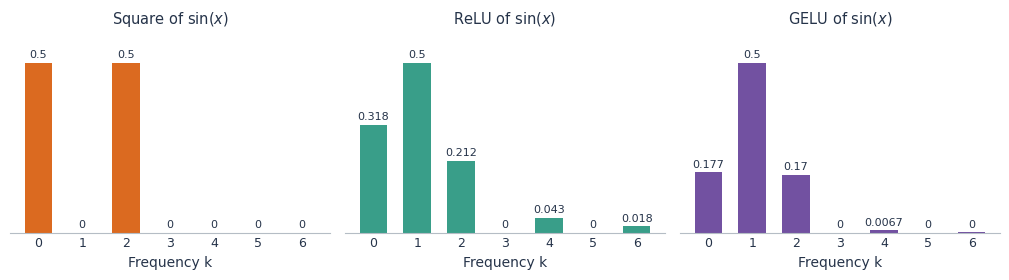

In [13]:
relu = np.maximum(z, 0)
gelu = 0.5*z*(1 + erf(z/np.sqrt(2)))
show_modes([(r'Square of $\sin(x)$', amplitudes(z**2, 6), ORANGE),
            (r'ReLU of $\sin(x)$', amplitudes(relu, 6), GREEN),
            (r'GELU of $\sin(x)$', amplitudes(gelu, 6), PURPLE)],
           np.arange(7), sharey=True)

All three activations turn the single wave into several. The square gives modes 0 and 2 only. ReLU keeps half of mode 1 and adds every even mode, with amplitudes $0.32$, $0.21$, and $0.04$ at modes 0, 2, and 4. GELU is smoother, so its new modes fall off faster, from $0.17$ at mode 2 to $0.007$ at mode 4.

Now imagine the next FNO layer receiving these new frequencies. Its learned $R_\ell(k)$ can transform them differently.

So the sequence becomes

$$\text{Modes}\;\xrightarrow{R_1}\;\text{Weighted modes}\;\xrightarrow{\sigma}\;\text{New modes}\;\xrightarrow{R_2}\;\text{New weighted modes}\;\xrightarrow{\sigma}\;\cdots$$

That is how nonlinear frequency mixing enters an FNO.

## 5. Limits and open questions

### Where does this approach struggle?

This distinction also explains some important FNO limitations.

| Physical challenge | Why it is difficult |
|---|---|
| Smooth diffusion | Relatively easy: low-frequency evolution often dominates |
| Nonlinear wave interactions | Requires enough layers and channels to learn the interactions |
| Shocks and discontinuities | Need many high-frequency modes to represent sharp changes |
| Turbulence | Important nonlinear interactions span many scales |
| Heterogeneous materials | Spatially varying properties couple Fourier modes |
| Complex boundaries | Standard Fourier bases are most natural for periodic domains |

A particularly important limitation is **spectral truncation**.

Most FNO implementations retain only a limited number of Fourier modes in their spectral branch. Nonlinear activations can still generate higher-frequency information, and the pointwise path can carry some of it. But the spectral branch cannot directly apply independent learned global transformations to frequencies that it discards.

This can be a serious limitation for shocks, interfaces, plastic localization, or contact mechanics.

On the [FNO block page](https://kks32-courses.github.io/sciml/05-fno/fno-block.html), choose the square wave with $k_{\max}=3$. The spectral branch returns a smooth curve, and the corners of the input survive only in the pointwise path.

### The most important intuition

FNO is not fundamentally about replacing a PDE solver with a neural network that predicts temperatures at individual points.

It is trying to learn a **mapping between functions**:

$$\boxed{\mathcal G:\underbrace{a(x)}_{\text{input function}}\longmapsto\underbrace{u(x)}_{\text{solution function}}}$$

For example, $a(x)$ could be the initial temperature or a spatially varying material property, and $u(x)$ could be the PDE solution at a chosen time.

A classical spectral solver derives how Fourier coefficients evolve using the governing equations.

An FNO uses training data to learn transformations of Fourier features that approximate the solution operator.

One important distinction: for a linear, constant-coefficient heat equation, individual Fourier modes evolve independently. For heterogeneous materials, boundaries, and nonlinear physics, they generally do not. FNO uses its nonlinear layers and channel mixing to model more complicated relationships, but this does not make it an exact general-purpose PDE solver.

**The mental model to keep:** A conventional neural network learns a relationship between numbers. A Fourier Neural Operator learns a relationship between entire fields, using Fourier waves as an efficient language for describing how one field transforms into another.

### The deeper research question

Here's the distinction that is most productive for understanding neural operators.

In a classical linear spectral method:

$$\widehat u_{t+\Delta t}(k)=R(k)\,\widehat u_t(k)$$

Each mode evolves independently.

For nonlinear dynamics, the Fourier evolution instead has the form

$$\frac{d\widehat u_k}{dt}=\underbrace{\lambda_k\widehat u_k}_{\text{linear evolution}}+\underbrace{\sum_{p,q:\,p+q=k}C(k,p,q)\,\widehat u_p\widehat u_q}_{\text{nonlinear interactions}}$$

where the coefficients $C$ depend on the governing PDE. For the Burgers equation, $\lambda_k=-\nu k^2$ and $C(k,p,q)=-ik/2$, because $u\,u_x=\tfrac12(u^2)_x$.

A standard FNO does not explicitly learn this interaction tensor $C(k,p,q)$. It learns the overall nonlinear operator implicitly through repeated Fourier transformations and pointwise nonlinearities.

That suggests two different scientific approaches:

**Approach A, standard FNO:** Learn a general mapping from input fields to solution fields, hoping the hidden features capture the necessary nonlinear interactions.

**Approach B, physics-structured neural operator:** Explicitly preserve known linear spectral dynamics, and learn only the unknown nonlinear interactions or closure terms.

For example:

$$\boxed{\frac{d\widehat u_k}{dt}=\lambda_k\widehat u_k+\mathcal N_\theta(\widehat u)_k}$$

Here, $\lambda_k$ comes from known mechanics, while $\mathcal N_\theta$ learns the unresolved or unknown coupling between modes. This is a possible research architecture, not a guarantee of better performance.

**The conceptual takeaway:** An FNO does not make the Fourier basis nonlinear. The basis stays fixed. Nonlinearity comes from repeatedly reconstructing the field in physical space, applying nonlinear transformations, and projecting back into Fourier space.

And the central limitation is that this indirect mechanism must learn complicated physical interactions from data, rather than having those interactions explicitly encoded by the governing equations.

And that leads to a deeper question relevant to FNO: **When the physics is nonlinear or spatially heterogeneous, can we discover a representation in which the evolution operator is approximately diagonal, instead of simply learning arbitrary Fourier weights?**

That connects Fourier Neural Operators to eigenfunction methods, reduced-order modeling, and Koopman operators.

Continue with the [CNN and discretization notebook](https://kks32-courses.github.io/sciml/05-fno/fno-cnn-comparisons.html), then the [FNO block](https://kks32-courses.github.io/sciml/05-fno/fno-block.html), and train the full network in the [Burgers and Darcy notebook](https://kks32-courses.github.io/sciml/05-fno/fno.html).

The [original FNO paper](https://arxiv.org/abs/2010.08895) gives the full architecture, and [McCabe et al., Section 2](https://arxiv.org/html/2306.10619v2) analyze the pseudo-spectral connection.